# Kucing vs Anjing: Transfer Learning dan Pemeriksaan Overfitting

Target eksperimen adalah **akurasi validation minimal 90%** dengan selisih
accuracy train bersih dan validation maksimal **5 poin persentase**.
Target merupakan kriteria penerimaan, bukan hasil yang diasumsikan tercapai.
Test hanya dibuka setelah seluruh pemilihan model selesai.

Kita memakai MobileNetV2 berbobot ImageNet sebagai ekstraktor fitur yang
dibekukan, lalu melatih classifier kecil dengan dropout dan L2.
Fitur disimpan agar setiap epoch tidak perlu menghitung ulang backbone di CPU.
Notebook CNN sebelumnya tetap tersedia sebagai eksperimen terpisah.

Referensi: [transfer learning Keras](https://keras.io/guides/transfer_learning/)
dan [MobileNetV2 Keras](https://keras.io/api/applications/mobilenet/).

## 1. Impor pustaka dan atur parameter

Seluruh gambar bersih dipakai. Split dan audit diambil dari run sebelumnya
agar hasil tidak dipengaruhi perubahan pembagian data. Bobot ImageNet perlu
diunduh sekali; sesudah tersimpan di cache Keras, internet tidak diperlukan.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor
import hashlib
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import accuracy_score, log_loss, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0


GPU: []


In [2]:
source_run = Path('outputs/20261022T024529_916223Z')
data_dir = Path('data/PetImages').resolve()
image_size = (160, 160)
image_batch_size = 32
head_batch_size = 128
maximum_epochs = 30
learning_rate = 0.001
target_accuracy = 0.90
maximum_overfit_gap = 0.05
seed = 42
class_names = ['Kucing', 'Anjing']
class_folders = ['Cat', 'Dog']
candidate_settings = [('dropout_030_l2_0001', 0.30, 0.0001),
                      ('dropout_050_l2_001', 0.50, 0.001)]
tf.keras.utils.set_random_seed(seed)
run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
run_dir = (Path('outputs') / ('transfer_' + run_id)).resolve()
run_dir.mkdir(parents=True, exist_ok=False)
print('Hasil:', run_dir)

Hasil: C:\Projecthabibibudiman\catvsdog\outputs\transfer_20261022T031434_475254Z


## 2. Baca split yang telah diaudit

Audit sebelumnya mengeluarkan file rusak, kelompok label bertentangan, serta
salinan identik. SHA-256 diperiksa lagi pada file saat ini agar cache fitur
tidak memakai gambar yang sudah berubah. Prosedur ini tidak mengubah label
atau split. Gambar mirip dengan encoding berbeda belum terdeteksi.

Jika proyek dipindahkan, atur `source_run` dan `data_dir`; nama file dan kelas
pada manifest tetap dipakai untuk menemukan gambar.

In [3]:
manifest_path = source_run / 'split_manifest.csv'
if not manifest_path.is_file():
    raise FileNotFoundError('Manifest belum tersedia. Jalankan tahap audit dan split notebook CNN dahulu.')
manifest = pd.read_csv(manifest_path)
required_columns = {'filepath', 'label', 'sha256', 'split'}
if not required_columns.issubset(manifest.columns):
    raise ValueError('Kolom manifest tidak lengkap.')
if manifest.empty or manifest['sha256'].duplicated().any():
    raise ValueError('Manifest kosong atau mengandung duplikat hash.')
if set(manifest['split']) != {'train', 'validation', 'test'}:
    raise ValueError('Manifest harus berisi train, validation, dan test.')
if set(manifest['label']) != {0, 1}:
    raise ValueError('Label harus 0 untuk kucing dan 1 untuk anjing.')
image_paths = []
for filepath, label in zip(manifest['filepath'], manifest['label']):
    image_paths.append(str(data_dir / class_folders[int(label)] / Path(filepath).name))
manifest['filepath'] = image_paths
manifest.to_csv(run_dir / 'split_manifest.csv', index=False)
print('Jumlah gambar:', len(manifest))
pd.crosstab(manifest['split'], manifest['label'])

Jumlah gambar: 24959


label,0,1
split,,
test,624,624
train,11230,11233
validation,624,624


In [4]:
def file_sha256(filepath):
    return hashlib.sha256(Path(filepath).read_bytes()).hexdigest()

with ThreadPoolExecutor(max_workers=4) as executor:
    current_hashes = list(executor.map(file_sha256, manifest['filepath']))
if current_hashes != manifest['sha256'].tolist():
    raise ValueError('Isi gambar berubah dari audit. Jalankan audit ulang sebelum memakai cache.')
train_df = manifest[manifest['split'] == 'train'].reset_index(drop=True)
validation_df = manifest[manifest['split'] == 'validation'].reset_index(drop=True)
test_df = manifest[manifest['split'] == 'test'].reset_index(drop=True)
train_labels = train_df['label'].to_numpy(dtype=np.float32)
validation_labels = validation_df['label'].to_numpy(dtype=np.float32)
print('Train / validation / test:', len(train_df), len(validation_df), len(test_df))

Train / validation / test: 22463 1248 1248


## 3. Siapkan pipeline gambar

Piksel RGB tetap pada rentang 0–255. Normalisasi MobileNetV2 ke rentang
−1 sampai 1 disimpan di model. Urutan dataset selalu sama dengan manifest,
sehingga fitur dan label tidak tertukar.

In [5]:
def load_image(filepath):
    image = tf.io.decode_image(tf.io.read_file(filepath), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    return tf.image.resize(tf.cast(image, tf.float32), image_size, antialias=True)

def make_image_dataset(frame):
    dataset = tf.data.Dataset.from_tensor_slices(frame['filepath'].to_numpy(dtype=str))
    dataset = dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return dataset.batch(image_batch_size).prefetch(tf.data.AUTOTUNE)

train_images = make_image_dataset(train_df)
validation_images = make_image_dataset(validation_df)

## 4. Bekukan backbone dan buat augmentasi

Semua bobot backbone dibekukan. Batch normalization selalu dipanggil dengan
`training=False` agar statistik ImageNet tidak diubah. Hanya gambar train
yang mendapat satu versi augmentasi: flip horizontal, rotasi ringan,
dan zoom ringan. Validation dan test tidak diberi augmentasi.

In [6]:
backbone = tf.keras.applications.MobileNetV2(
    input_shape=(image_size[0], image_size[1], 3),
    include_top=False, weights='imagenet', pooling='avg',
)
backbone.trainable = False
image_input = tf.keras.Input(shape=(image_size[0], image_size[1], 3))
normalized_image = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1.0)(image_input)
image_features = backbone(normalized_image, training=False)
feature_extractor = tf.keras.Model(image_input, image_features, name='feature_extractor')
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal', seed=seed),
    tf.keras.layers.RandomRotation(0.04, fill_mode='nearest', seed=seed + 1),
    tf.keras.layers.RandomZoom(0.1, fill_mode='nearest', seed=seed + 2),
], name='train_augmentation')
print('Bobot backbone yang dilatih:', len(backbone.trainable_weights))
print('Jumlah fitur per gambar:', feature_extractor.output_shape[-1])

Bobot backbone yang dilatih: 0
Jumlah fitur per gambar: 1280


## 5. Ekstrak dan simpan fitur train serta validation

Ekstraksi ini hanya dilakukan sekali untuk setiap kombinasi manifest,
versi pustaka, ukuran gambar, seed, dan aturan augmentasi. Fitur clean train
dan versi augmented dipakai bersama saat melatih classifier. Ini merupakan
augmentasi statis satu versi per gambar, bukan variasi baru setiap epoch.
Test belum diekstrak pada tahap ini.

In [7]:
cache_description = {
    'manifest_sha256': file_sha256(manifest_path),
    'backbone': 'MobileNetV2_1.0_ImageNet_frozen',
    'tensorflow': tf.__version__, 'keras': tf.keras.__version__,
    'image_size': list(image_size), 'seed': seed,
    'augmentation': 'flip_horizontal_rotation004_zoom01',
    'preprocessing': 'RGB_resize_antialias_rescale1275_offset_minus1',
    'cache_version': 1,
}
cache_key = hashlib.sha256(json.dumps(cache_description, sort_keys=True).encode()).hexdigest()[:20]
cache_dir = Path('data/feature_cache') / cache_key
cache_dir.mkdir(parents=True, exist_ok=True)
(cache_dir / 'metadata.json').write_text(json.dumps(cache_description, indent=2), encoding='utf-8')

def extract_features(dataset, cache_name, expected_rows):
    cache_path = cache_dir / (cache_name + '.npy')
    if cache_path.is_file():
        features = np.load(cache_path)
        print('Cache dipakai:', cache_name)
    else:
        print('Ekstraksi:', cache_name)
        features = feature_extractor.predict(dataset, verbose=1)
        np.save(cache_path, features)
    if features.shape != (expected_rows, 1280) or not np.isfinite(features).all():
        raise ValueError('Cache fitur tidak sesuai bentuk atau mengandung nilai tidak valid.')
    return features

In [8]:
train_features = extract_features(train_images, 'train_clean', len(train_df))
validation_features = extract_features(validation_images, 'validation_clean', len(validation_df))

def augment_batch(images):
    return augmentation(images, training=True)

augmented_images = train_images.map(augment_batch, num_parallel_calls=1)
augmented_features = extract_features(augmented_images, 'train_augmented', len(train_df))
training_features = np.concatenate([train_features, augmented_features], axis=0)
training_labels = np.concatenate([train_labels, train_labels], axis=0)
print('Fitur training:', training_features.shape)
print('Fitur validation:', validation_features.shape)

Ekstraksi: train_clean


  1/702 ━━━━━━━━━━━━━━━━━━━━ 27:42 2s/step

  2/702 ━━━━━━━━━━━━━━━━━━━━ 3:25 293ms/step

  3/702 ━━━━━━━━━━━━━━━━━━━━ 3:34 307ms/step

  4/702 ━━━━━━━━━━━━━━━━━━━━ 3:31 303ms/step

  5/702 ━━━━━━━━━━━━━━━━━━━━ 3:26 296ms/step

... (1,440 outputs left out)

701/702 ━━━━━━━━━━━━━━━━━━━━ 0s 436ms/step

702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 436ms/step

702/702 ━━━━━━━━━━━━━━━━━━━━ 307s 436ms/step


Fitur training: (44926, 1280)
Fitur validation: (1248, 1280)


## 6. Latih dua classifier dengan regularisasi

Classifier hanya memiliki 1.281 parameter yang dilatih. Dropout dan L2
membatasi ketergantungan pada fitur tertentu. Early stopping mengembalikan
checkpoint validation loss terbaik, dan learning rate dikurangi bila
validation loss berhenti membaik. Kita membandingkan dua kekuatan
regularisasi yang ditentukan di awal, memakai validation saja.

Gap dihitung dari **clean train pada mode inference** dan validation,
bukan dari accuracy training yang masih memakai dropout dan augmentasi.
Log loss tanpa penalti L2 dipakai untuk membandingkan kandidat agar besarnya
penalti antarclassifier tidak memengaruhi perbandingan.

In [9]:
def build_head(dropout_rate, l2_strength):
    head = tf.keras.Sequential([
        tf.keras.Input(shape=(1280,)),
        tf.keras.layers.Dropout(dropout_rate, seed=seed),
        tf.keras.layers.Dense(
            1, activation='sigmoid',
            kernel_regularizer=tf.keras.regularizers.l2(l2_strength),
            kernel_initializer=tf.keras.initializers.GlorotUniform(seed=seed),
        ),
    ], name='cat_dog_head')
    head.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy', metrics=['accuracy'],
    )
    return head

candidate_rows = []
histories = {}

In [10]:
for candidate_name, dropout_rate, l2_strength in candidate_settings:
    tf.keras.utils.set_random_seed(seed)
    head = build_head(dropout_rate, l2_strength)
    checkpoint = run_dir / (candidate_name + '.keras')
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(str(checkpoint), monitor='val_loss', save_best_only=True),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, min_delta=0.0001, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=0.000001),
    ]
    print('Training:', candidate_name)
    history = head.fit(
        training_features, training_labels,
        validation_data=(validation_features, validation_labels),
        batch_size=head_batch_size, epochs=maximum_epochs,
        callbacks=callbacks, shuffle=True, verbose=2,
    )
    histories[candidate_name] = history.history
    pd.DataFrame(history.history).to_csv(run_dir / (candidate_name + '_history.csv'), index=False)
    head = tf.keras.models.load_model(checkpoint)
    clean_train_scores = head.predict(train_features, batch_size=256, verbose=0).ravel()
    validation_scores = head.predict(validation_features, batch_size=256, verbose=0).ravel()
    train_accuracy = accuracy_score(train_labels, clean_train_scores >= 0.5)
    validation_accuracy = accuracy_score(validation_labels, validation_scores >= 0.5)
    overfit_gap = float(train_accuracy - validation_accuracy)
    candidate_rows.append({
        'candidate': candidate_name, 'clean_train_accuracy': float(train_accuracy),
        'validation_accuracy': float(validation_accuracy), 'overfit_gap': overfit_gap,
        'validation_log_loss': float(log_loss(validation_labels, validation_scores, labels=[0, 1])),
        'meets_validation_target': bool(validation_accuracy >= target_accuracy and overfit_gap <= maximum_overfit_gap),
        'epochs_run': len(history.history['loss']), 'checkpoint': str(checkpoint),
        'dropout': dropout_rate, 'l2': l2_strength,
    })
    print(candidate_rows[-1])
    pd.DataFrame(candidate_rows).to_csv(run_dir / 'validation_comparison.csv', index=False)

Training: dropout_030_l2_0001


Epoch 1/30


351/351 - 3s - 8ms/step - accuracy: 0.9522 - loss: 0.1190 - val_accuracy: 0.9760 - val_loss: 0.0498 - learning_rate: 0.0010


Epoch 2/30


351/351 - 2s - 5ms/step - accuracy: 0.9763 - loss: 0.0641 - val_accuracy: 0.9800 - val_loss: 0.0445 - learning_rate: 0.0010


Epoch 3/30


... (41 outputs left out)

351/351 - 2s - 4ms/step - accuracy: 0.9760 - loss: 0.0684 - val_accuracy: 0.9848 - val_loss: 0.0438 - learning_rate: 5.0000e-04


Epoch 11/30


351/351 - 1s - 4ms/step - accuracy: 0.9764 - loss: 0.0667 - val_accuracy: 0.9824 - val_loss: 0.0440 - learning_rate: 5.0000e-04


{'candidate': 'dropout_050_l2_001', 'clean_train_accuracy': 0.98504206918043, 'validation_accuracy': 0.9815705128205128, 'overfit_gap': 0.0034715563599172494, 'validation_log_loss': 0.039421942085027695, 'meets_validation_target': True, 'epochs_run': 11, 'checkpoint': 'C:\\Projecthabibibudiman\\catvsdog\\outputs\\transfer_20261022T031434_475254Z\\dropout_050_l2_001.keras', 'dropout': 0.5, 'l2': 0.001}


## 7. Pilih model tanpa melihat test

Prioritaskan kandidat yang mencapai target validation dan batas gap.
Di antara kandidat yang lolos, pilih validation log loss terendah.
Jika tidak ada yang lolos, notebook melaporkan target belum tercapai dan
tetap memilih kandidat dengan validation log loss terendah secara jujur.

In [11]:
comparison = pd.DataFrame(candidate_rows)
eligible = comparison[comparison['meets_validation_target']]
selection_pool = eligible
if eligible.empty:
    selection_pool = comparison
    print('Target validation belum tercapai. Jangan mengklaim accuracy 90%.')
selected = selection_pool.sort_values('validation_log_loss').iloc[0]
selected_head = tf.keras.models.load_model(selected['checkpoint'])
selection = selected.to_dict()
(run_dir / 'selection.json').write_text(json.dumps(selection, indent=2), encoding='utf-8')
print('Kandidat terpilih:', selected['candidate'])
comparison[['candidate', 'clean_train_accuracy', 'validation_accuracy', 'overfit_gap', 'meets_validation_target']]

Kandidat terpilih: dropout_030_l2_0001


,candidate,clean_train_accuracy,validation_accuracy,overfit_gap,meets_validation_target
0,dropout_030_l2_0001,0.987758,0.981571,0.006187,True
1,dropout_050_l2_001,0.985042,0.981571,0.003472,True


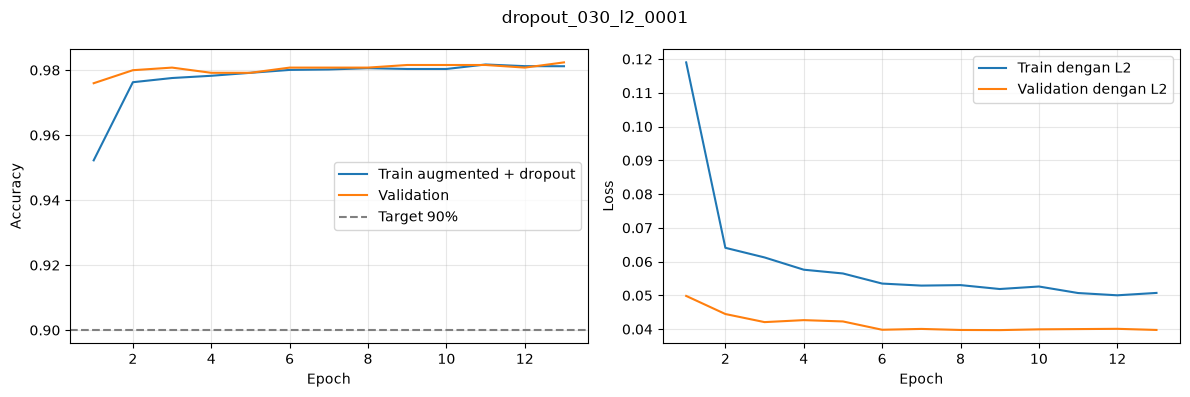

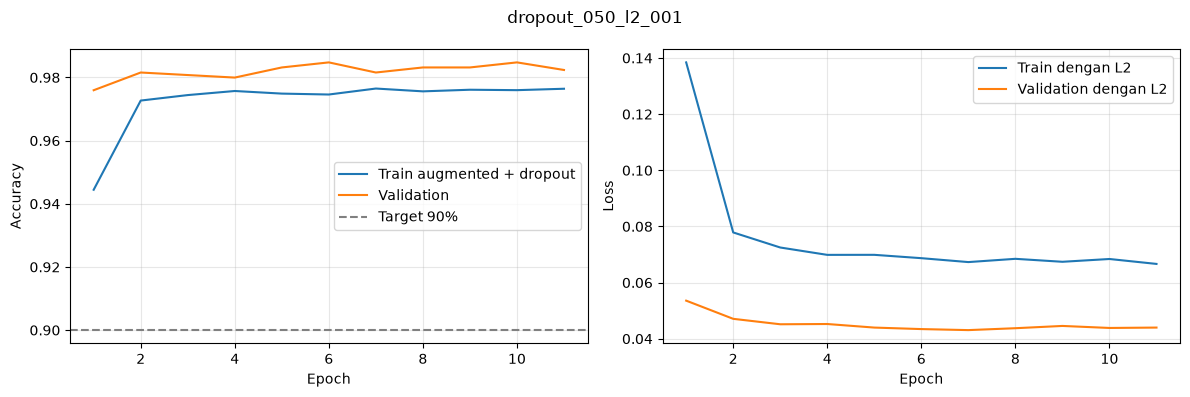

In [12]:
for candidate_name, history_values in histories.items():
    epoch_numbers = range(1, len(history_values['loss']) + 1)
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epoch_numbers, history_values['accuracy'], label='Train augmented + dropout')
    axes[0].plot(epoch_numbers, history_values['val_accuracy'], label='Validation')
    axes[0].axhline(target_accuracy, color='gray', linestyle='--', label='Target 90%')
    axes[0].set_ylabel('Accuracy')
    axes[1].plot(epoch_numbers, history_values['loss'], label='Train dengan L2')
    axes[1].plot(epoch_numbers, history_values['val_loss'], label='Validation dengan L2')
    axes[1].set_ylabel('Loss')
    for axis in axes:
        axis.set_xlabel('Epoch')
        axis.legend()
        axis.grid(alpha=0.3)
    figure.suptitle(candidate_name)
    plt.tight_layout()
    plt.show()

## 8. Simpan model lengkap dan periksa konsistensi prediksi

Model ekspor menerima gambar RGB float32 berukuran 160 × 160 pada rentang
0–255. Normalisasi sudah berada di dalam model. Satu keluaran sigmoid
adalah skor Anjing; skor Kucing adalah satu dikurangi skor Anjing.
Kita memeriksa bahwa model lengkap dan classifier pada cache memberi skor
yang sama sebelum menyentuh test.

In [13]:
final_input = tf.keras.Input(shape=(image_size[0], image_size[1], 3), name='image')
final_features = feature_extractor(final_input, training=False)
final_scores = selected_head(final_features, training=False)
final_model = tf.keras.Model(final_input, final_scores, name='cats_dogs_mobilenetv2')
model_path = run_dir / 'best_model.keras'
final_model.save(model_path)
reloaded_model = tf.keras.models.load_model(model_path)
sample_images = next(iter(validation_images))
cached_scores = selected_head(validation_features[:len(sample_images)], training=False).numpy()
exported_scores = reloaded_model(sample_images, training=False).numpy()
if not np.allclose(cached_scores, exported_scores, rtol=0.0001, atol=0.00001):
    raise ValueError('Prediksi model ekspor berbeda dari classifier pada fitur cache.')
print('Model tersimpan dan prediksi hasil reload cocok:', model_path)

Model tersimpan dan prediksi hasil reload cocok: C:\Projecthabibibudiman\catvsdog\outputs\transfer_20261022T031434_475254Z\best_model.keras


## 9. Evaluasi akhir test sekali setelah pemilihan

Baru sekarang fitur test dihitung. Test tidak dipakai untuk memilih
classifier, epoch, dropout, L2, atau threshold (tetap 0,5).
Hasil test dilaporkan apa adanya; test tidak dipakai untuk menyesuaikan model
lagi. Gap kecil adalah indikator, bukan bukti mutlak bebas overfitting.

In [14]:
test_features = extract_features(make_image_dataset(test_df), 'test_clean', len(test_df))
test_labels = test_df['label'].to_numpy(dtype=np.int32)
dog_scores = selected_head.predict(test_features, batch_size=256, verbose=0).ravel()
test_predictions = (dog_scores >= 0.5).astype(np.int32)
report = classification_report(
    test_labels, test_predictions, labels=[0, 1], target_names=class_names,
    output_dict=True, zero_division=0,
)
test_metrics = {
    'test_accuracy': float(accuracy_score(test_labels, test_predictions)),
    'test_log_loss': float(log_loss(test_labels, dog_scores, labels=[0, 1])),
    'macro_f1': float(report['macro avg']['f1-score']),
    'roc_auc_dog_positive': float(roc_auc_score(test_labels, dog_scores)),
    'test_samples': int(len(test_df)),
}
(run_dir / 'test_metrics.json').write_text(json.dumps(test_metrics, indent=2), encoding='utf-8')
pd.DataFrame(report).transpose().to_csv(run_dir / 'classification_report.csv')
print(json.dumps(test_metrics, indent=2))
pd.DataFrame(report).transpose()

Ekstraksi: test_clean


 1/39 ━━━━━━━━━━━━━━━━━━━━ 1:03 2s/step

 2/39 ━━━━━━━━━━━━━━━━━━━━ 18s 490ms/step

 3/39 ━━━━━━━━━━━━━━━━━━━━ 18s 511ms/step

 4/39 ━━━━━━━━━━━━━━━━━━━━ 18s 522ms/step

 5/39 ━━━━━━━━━━━━━━━━━━━━ 17s 505ms/step

... (33 outputs left out)

39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step

39/39 ━━━━━━━━━━━━━━━━━━━━ 18s 434ms/step


{
  "test_accuracy": 0.9791666666666666,
  "test_log_loss": 0.05818116292357445,
  "macro_f1": 0.9791666131621188,
  "roc_auc_dog_positive": 0.9973008095003287,
  "test_samples": 1248
}


,precision,recall,f1-score,support
Kucing,0.980707,0.977564,0.979133,624.000000
Anjing,0.977636,0.980769,0.979200,624.000000
accuracy,0.979167,0.979167,0.979167,0.979167
macro avg,0.979172,0.979167,0.979167,1248.000000
weighted avg,0.979172,0.979167,0.979167,1248.000000


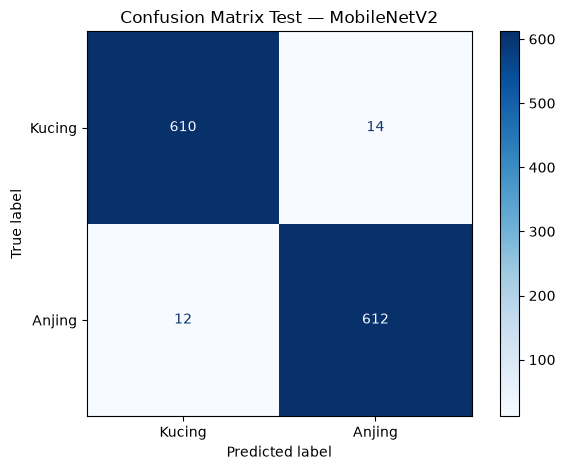

In [15]:
predictions = test_df.copy()
predictions['score_anjing'] = dog_scores
predictions['score_kucing'] = 1 - dog_scores
predictions['predicted_label'] = test_predictions
predictions['correct'] = test_labels == test_predictions
predictions.to_csv(run_dir / 'test_predictions.csv', index=False)
matrix = confusion_matrix(test_labels, test_predictions, labels=[0, 1])
ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix Test — MobileNetV2')
plt.tight_layout()
plt.show()

## 10. Ringkas target dan indikasi overfitting

Kriteria awal harus dilaporkan bersama hasil akhir: validation ≥90%,
gap clean train–validation ≤5 poin persentase, dan test ≥90% sebagai
konfirmasi pada holdout. Angka ini tidak membuktikan generalisasi ke semua
foto di luar dataset. Split berdasarkan gambar dan hash identik belum
memisahkan foto mirip atau semua foto hewan yang sama.

In [16]:
summary = {
    'run_dir': str(run_dir), 'source_audit_run': str(source_run),
    'manifest_sha256': cache_description['manifest_sha256'],
    'model': 'MobileNetV2 ImageNet frozen + dropout/L2 binary classifier',
    'model_path': str(model_path), 'cache_dir': str(cache_dir.resolve()),
    'train_samples': int(len(train_df)), 'validation_samples': int(len(validation_df)),
    'test_samples': int(len(test_df)), 'selected_candidate': str(selected['candidate']),
    'clean_train_accuracy': float(selected['clean_train_accuracy']),
    'validation_accuracy': float(selected['validation_accuracy']),
    'train_validation_gap': float(selected['overfit_gap']),
    'validation_target_met': bool(selected['meets_validation_target']),
    'test_target_met': bool(test_metrics['test_accuracy'] >= target_accuracy),
    'target_accuracy': target_accuracy, 'maximum_overfit_gap': maximum_overfit_gap,
    'test_metrics': test_metrics, 'image_size': list(image_size),
    'input_range': [0, 255], 'class_names': class_names,
    'threshold': 0.5, 'seed': seed, 'tensorflow': tf.__version__,
}
(run_dir / 'run_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(f"Train bersih: {summary['clean_train_accuracy']:.2%}")
print(f"Validation: {summary['validation_accuracy']:.2%}")
print(f"Gap train-validation: {100 * summary['train_validation_gap']:.2f} poin persentase")
print(f"Test: {test_metrics['test_accuracy']:.2%}")
print('Target validation dan batas gap terpenuhi:', summary['validation_target_met'])
print('Target test terpenuhi:', summary['test_target_met'])
print('Model dan artefak:', run_dir)

Train bersih: 98.78%
Validation: 98.16%
Gap train-validation: 0.62 poin persentase
Test: 97.92%
Target validation dan batas gap terpenuhi: True
Target test terpenuhi: True
Model dan artefak: C:\Projecthabibibudiman\catvsdog\outputs\transfer_20261022T031434_475254Z


## 11. Coba gambar sendiri

Isi `prediction_path` dengan path gambar. Skor model belum tentu
terkalibrasi; gambar selain kucing/anjing tetap dipaksa ke salah satu kelas.

In [17]:
prediction_path = None
if prediction_path is None:
    print('Isi prediction_path dengan Path menuju gambar yang ingin diprediksi.')
else:
    new_image = load_image(str(prediction_path))
    dog_score = float(reloaded_model(tf.expand_dims(new_image, 0), training=False).numpy()[0, 0])
    predicted_label = int(dog_score >= 0.5)
    print('Prediksi:', class_names[predicted_label])
    print(f'Skor Anjing: {dog_score:.2%}; skor Kucing: {1 - dog_score:.2%}')
    plt.imshow(new_image.numpy().astype('uint8'))
    plt.title(class_names[predicted_label])
    plt.axis('off')
    plt.show()

Isi prediction_path dengan Path menuju gambar yang ingin diprediksi.
